# Reproduction: Tshitoyan et al. (2019) on cs.IR, a historical backtest

Paper 12, IR 2 seminar. This notebook **reads cached artefacts** produced by the scripts in `ir2/scripts/`; each section names the command that regenerates them. Decisions and deviations are in `ir2/NOTES.md`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
IR2 = Path('.').resolve()
R, F = IR2 / 'results', IR2 / 'figures'
show = lambda p: display(Markdown((R / p).read_text()))

## Phase 1: dated corpus (Kaggle arXiv snapshot, 2026-11-08)
`python ir2/scripts/phase1_corpus.py`

,cs.IR (any),cs.IR (primary),cs.CL (any),cs.CL not cs.IR
year,,,,
2008,85,40,70,56
2009,161,87,91,80
2010,180,110,86,78
2011,201,119,125,113
2012,405,225,225,164
2013,386,215,334,273
2014,421,225,557,464
2015,495,244,832,718
2016,575,288,1692,1508


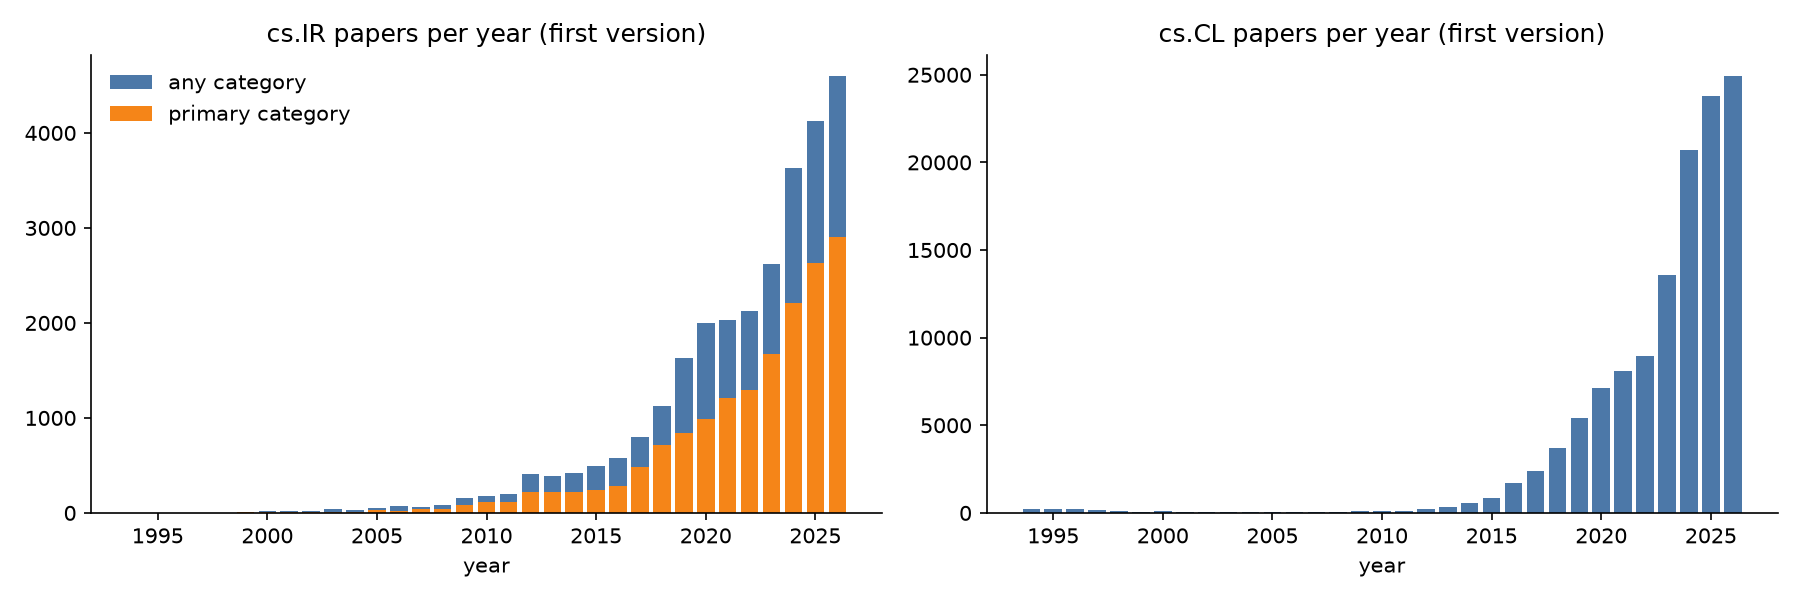

In [2]:
counts = pd.read_csv(R / 'phase1_counts.csv', index_col='year')
display(counts.loc[2008:])
display(Image(F / 'phase1_counts.png'))

## Phase 2: preprocessing with a phraser learned before each cutoff
`python ir2/scripts/phase2_preprocess.py`

In [3]:
show('phase2_cutoffs.md')

# Phase 2: per-cutoff preprocessing

- T=2016: 5,744 train docs (845,705 tokens), 25,267 post cs.IR docs, 1,673 phrasegrams, vocab 8,284 (890 phrases), 9s
- T=2017: 7,682 train docs (1,150,491 tokens), 24,692 post cs.IR docs, 2,403 phrasegrams, vocab 9,766 (1,293 phrases), 11s
- T=2018: 10,513 train docs (1,599,686 tokens), 23,898 post cs.IR docs, 3,338 phrasegrams, vocab 11,614 (1,817 phrases), 12s
- T=2019: 14,793 train docs (2,285,282 tokens), 22,771 post cs.IR docs, 4,626 phrasegrams, vocab 14,035 (2,583 phrases), 15s
- T=2020: 20,869 train docs (3,296,998 tokens), 21,140 post cs.IR docs, 6,418 phrasegrams, vocab 17,109 (3,603 phrases), 19s
- T=2021: 28,834 train docs (4,673,688 tokens), 19,142 post cs.IR docs, 8,523 phrasegrams, vocab 20,789 (4,809 phrases), 24s
- T=2022: 38,196 train docs (6,332,539 tokens), 17,112 post cs.IR docs, 10,833 phrasegrams, vocab 24,858 (6,168 phrases), 30s
- T=2023: 48,486 train docs (8,203,760 tokens), 14,987 post cs.IR docs, 13,084 phrasegrams, vocab 29,076 (7,519 phrases), 36s


## Phase 3: the backtest
`python ir2/scripts/phase3_train.py && python ir2/scripts/phase3_encode.py && python ir2/scripts/phase3_backtest.py && python ir2/scripts/phase3_report.py --hero recommender_systems 2017`

Mean precision over the scored (target, T) pairs; word2vec is averaged over 3 seeds.

In [4]:
bt = pd.read_csv(R / 'backtest.csv')
bt = bt[bt.w2v_target_in_vocab]
(bt.groupby(['setting', 'method'])[['p10', 'p20', 'p50', 'p50_freq_matched']].mean()
   .assign(beyond_frequency=lambda d: d.p50 - d.p50_freq_matched).round(3))

p10    p20    p50  p50_freq_matched  beyond_frequency
setting method                                                            
all     cooc2      0.827  0.817  0.785             0.410             0.375
        frequency  0.533  0.547  0.576             0.419             0.157
        random     0.148  0.149  0.149               NaN               NaN
        specter2   0.567  0.523  0.498             0.215             0.283
        w2v_in     0.098  0.093  0.099             0.073             0.027
        w2v_out    0.306  0.315  0.308             0.208             0.099
phrases cooc2      0.630  0.591  0.512             0.221             0.290
        frequency  0.430  0.395  0.341             0.242             0.099
        random     0.110  0.110  0.110               NaN               NaN
        specter2   0.509  0.459  0.403             0.132             0.271
        w2v_in     0.183  0.161  0.156             0.083             0.073
        w2v_out    0.323  0.304  0.270             0.137             0.133

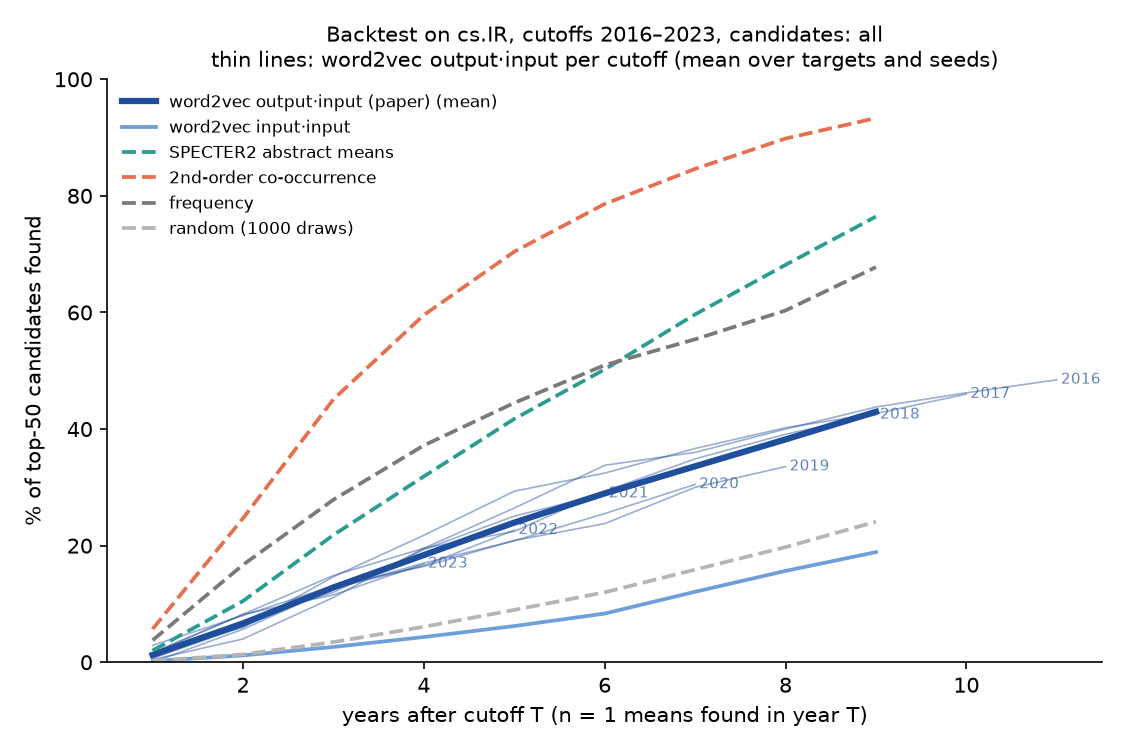

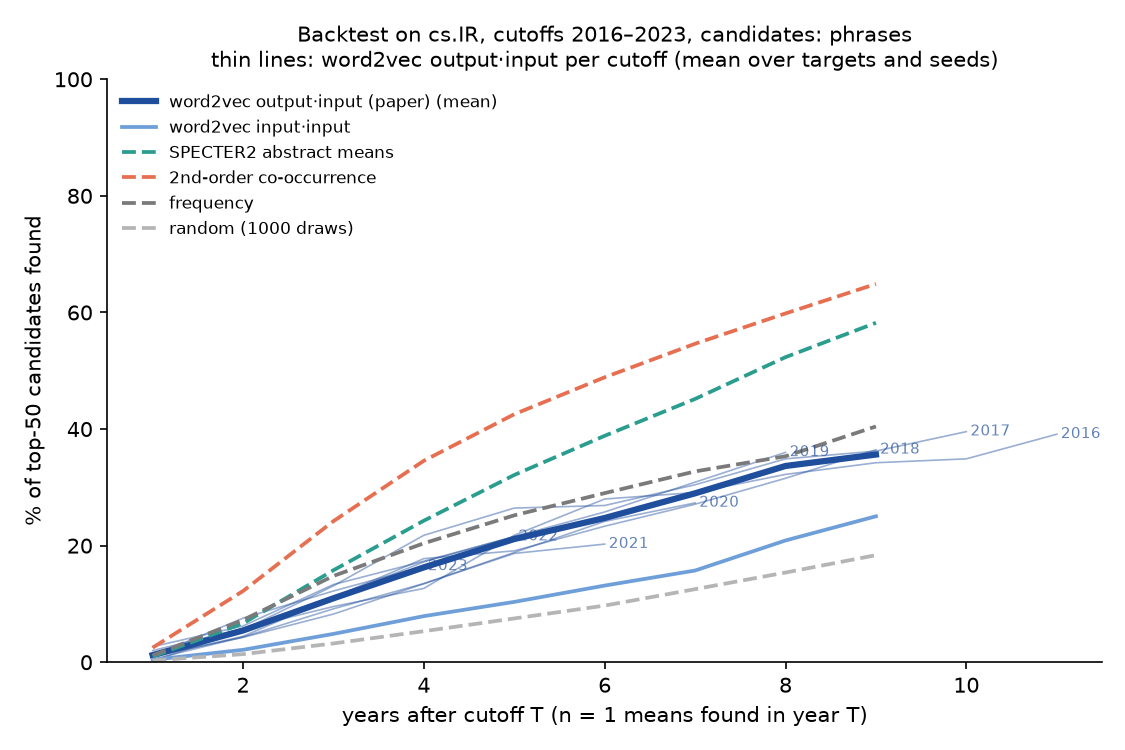

In [5]:
display(Image(F / 'fig3a_all.png'))
display(Image(F / 'fig3a_phrases.png'))

Per-seed spread of the paper's scoring (mean P@50 over pairs):

In [6]:
bt[bt.method.str.startswith('w2v')].groupby(['setting', 'method', 'seed']).p50.mean().unstack('seed').round(3)

seed                 0      1      2
setting method                      
all     w2v_in   0.097  0.102  0.099
        w2v_out  0.310  0.299  0.313
phrases w2v_in   0.156  0.152  0.161
        w2v_out  0.271  0.267  0.273

Hero list (chosen after seeing every pair):

In [7]:
show('hero_top20.md')

# Hero list: `learning_to_rank`, cutoff T = 2020, candidates `phrases`

Trained on cs.IR ∪ cs.CL abstracts before 2020. Candidates never appear in an abstract with a `learning_to_rank` indicator before 2020. ✓ = appears with an indicator in ≥ 3 cs.IR abstracts from 2020 on (year the third one appeared).

| rank | word2vec output·input (paper) | found | frequency baseline | found |
|:-:|---|:-:|---|:-:|
| 1 | `multi_armed_bandit` | ✗ | `sentiment_analysis` | ✗ |
| 2 | `personalized_ranking` | ✓ 2024 | `neural_machine_translation` | ✗ |
| 3 | `matrix_factorisation` | ✗ | `speech_recognition` | ✗ |
| 4 | `fairness_aware` | ✗ | `cross_lingual` | ✓ 2025 |
| 5 | `root_mean_square_error` | ✗ | `language_modeling` | ✓ 2024 |
| 6 | `directly_optimizes` | ✗ | `recurrent_neural_networks` | ✗ |
| 7 | `latent_factor` | ✗ | `relation_extraction` | ✗ |
| 8 | `outperforms_state_of_the_art` | ✓ 2023 | `information_extraction` | ✗ |
| 9 | `meta_learning` | ✗ | `character_level` | ✗ |
| 10 | `negative_sampling` | ✓ 2024 | `named_entity_recognition` | ✗ |
| 11 | `recommendation_algorithms` | ✓ 2024 | `word_representations` | ✗ |
| 12 | `large_margin` | ✓ 2025 | `topic_modeling` | ✗ |
| 13 | `page_rank` | ✗ | `text_generation` | ✗ |
| 14 | `linear_regression` | ✗ | `sentiment_classification` | ✗ |
| 15 | `bandit_feedback` | ✗ | `encoder_decoder` | ✗ |
| 16 | `state_of_the_art_baselines` | ✓ 2026 | `neural_machine_translation_nmt` | ✗ |
| 17 | `rating_prediction` | ✗ | `nlp_tasks` | ✗ |
| 18 | `ctr_prediction` | ✓ 2022 | `semantic_parsing` | ✗ |
| 19 | `euclidean_distance` | ✗ | `low_resource` | ✗ |
| 20 | `link_prediction` | ✗ | `rule_based` | ✗ |

word2vec: 7/20 found · frequency: 2/20 found


Every (target, T) pair and why it was or was not scored:

In [8]:
pd.read_csv(R / 'backtest_status.csv')[['target', 'T', 'status', 'pre_T_target_docs', 'post_T_target_docs', 'n_candidates_all', 'base_rate_all']]

,target,T,status,pre_T_target_docs,post_T_target_docs,n_candidates_all,base_rate_all
0,query_expansion,2016,scored,71,438,6330,0.165719
1,recommender_systems,2016,scored,373,8729,4026,0.557129
2,learning_to_rank,2016,scored,18,563,7405,0.273464
3,dense_retrieval,2016,target not in vocabulary,0,824,8134,0.375338
4,conversational_search,2016,target not in vocabulary,0,370,8134,0.242193
5,retrieval_augmented_generation,2016,target not in vocabulary,0,2136,8134,0.567126
6,query_expansion,2017,scored,84,424,7546,0.134773
7,recommender_systems,2017,scored,522,8586,4558,0.489030
8,learning_to_rank,2017,scored,34,549,8420,0.215558
9,dense_retrieval,2017,target not in vocabulary,0,824,9585,0.337924
